In [ ]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
df = pd.read_csv("credit_scoring_train[1].csv")
print(df.shape)
print(df.columns.tolist())
df.head()

(75000, 11)
['client_id', 'DIR', 'Age', 'NumLoans', 'NumRealEstateLoans', 'NumDependents', 'Num30-59Delinquencies', 'Num60-89Delinquencies', 'Income', 'BalanceToCreditLimit', 'Delinquent90']


,client_id,DIR,Age,NumLoans,NumRealEstateLoans,NumDependents,Num30-59Delinquencies,Num60-89Delinquencies,Income,BalanceToCreditLimit,Delinquent90
0,0,0.496289,49.1,13,0,0.0,2,0,5298.360639,0.387028,0
1,1,0.433567,48.0,9,2,2.0,1,0,6008.056256,0.234679,0
2,2,2206.731199,55.5,21,1,NaN,1,0,NaN,0.348227,0
3,3,886.132793,55.3,3,0,0.0,0,0,NaN,0.971930,0
4,4,0.000000,52.3,1,0,0.0,0,0,2504.613105,1.004350,0


In [ ]:
for c in df.columns:
    print(c, "|", df[c].nunique(), "unique |", df[c].isna().sum(), "missing")

print("\nLikely target (only 2 values):",
      [c for c in df.columns if df[c].nunique() == 2])

client_id | 75000 unique | 0 missing
DIR | 70376 unique | 0 missing
Age | 527 unique | 0 missing
NumLoans | 55 unique | 0 missing
NumRealEstateLoans | 24 unique | 0 missing
NumDependents | 13 unique | 1916 missing
Num30-59Delinquencies | 16 unique | 0 missing
Num60-89Delinquencies | 11 unique | 0 missing
Income | 59346 unique | 14847 missing
BalanceToCreditLimit | 63413 unique | 0 missing
Delinquent90 | 2 unique | 0 missing

Likely target (only 2 values): ['Delinquent90']


In [ ]:
cands = [c for c in df.columns if df[c].nunique() == 2 and c != "client_id"]
print("Target candidates:", cands)
TARGET = cands[-1]          # if wrong, type the right name here
print("Using:", TARGET)
print(df[TARGET].value_counts())
print(df[TARGET].value_counts(normalize=True).round(3))

Target candidates: ['Delinquent90']
Using: Delinquent90
Delinquent90
0    69987
1     5013
Name: count, dtype: int64
Delinquent90
0    0.933
1    0.067
Name: proportion, dtype: float64


In [ ]:
df = df.drop_duplicates().copy()

# new features from financial history
delinq = [c for c in df.columns if "Delinq" in c]
df["TotalDelinq"] = df[delinq].sum(axis=1)
df["AnyDelinq"] = (df["TotalDelinq"] > 0).astype(int)
df["IncomeMissing"] = df["Income"].isna().astype(int)
df["DIR"] = df["DIR"].clip(upper=df["DIR"].quantile(0.99))   # cap extreme values

y = df[TARGET]
X = df.drop(columns=[TARGET, "client_id"])
X = pd.get_dummies(X, drop_first=True, dtype=int)
X = X.fillna(X.median())
print(X.shape)
X.head()

(75000, 12)


,DIR,Age,NumLoans,NumRealEstateLoans,NumDependents,Num30-59Delinquencies,Num60-89Delinquencies,Income,BalanceToCreditLimit,TotalDelinq,AnyDelinq,IncomeMissing
0,0.496289,49.1,13,0,0.0,2,0,5298.360639,0.387028,2,1,0
1,0.433567,48.0,9,2,2.0,1,0,6008.056256,0.234679,1,1,0
2,2206.731199,55.5,21,1,0.0,1,0,5424.552473,0.348227,1,1,1
3,886.132793,55.3,3,0,0.0,0,0,5424.552473,0.971930,0,0,1
4,0.000000,52.3,1,0,0.0,0,0,2504.613105,1.004350,0,0,0


===== Logistic Regression
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     13997
           1       1.00      1.00      1.00      1003

    accuracy                           1.00     15000
   macro avg       1.00      1.00      1.00     15000
weighted avg       1.00      1.00      1.00     15000

===== Decision Tree
              precision    recall  f1-score   support

           0       1.00      0.97      0.99     13997
           1       0.73      1.00      0.84      1003

    accuracy                           0.97     15000
   macro avg       0.86      0.99      0.91     15000
weighted avg       0.98      0.97      0.98     15000

===== Random Forest
              precision    recall  f1-score   support

           0       1.00      0.96      0.98     13997
           1       0.63      1.00      0.77      1003

    accuracy                           0.96     15000
   macro avg       0.82      0.98      0.88     15000
weighted

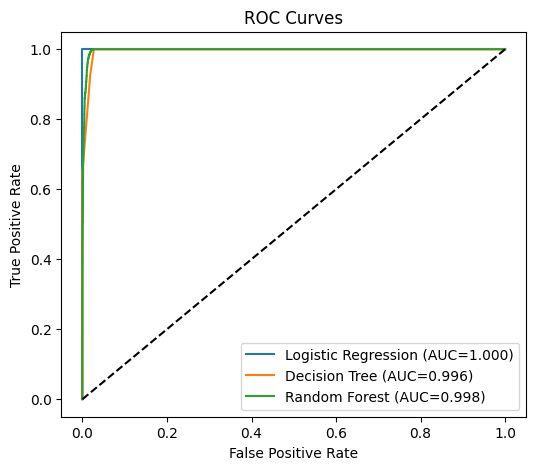

,Model,Precision,Recall,F1,ROC_AUC
0,Logistic Regression,1.000,1.0,1.000,1.000
1,Decision Tree,0.726,1.0,0.841,0.996
2,Random Forest,0.631,1.0,0.774,0.998


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, roc_curve, precision_score, recall_score, f1_score

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

models = {
 "Logistic Regression": make_pipeline(StandardScaler(),
        LogisticRegression(class_weight="balanced", max_iter=1000)),
 "Decision Tree": DecisionTreeClassifier(max_depth=5, min_samples_leaf=50,
        class_weight="balanced", random_state=42),
 "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=8,
        min_samples_leaf=20, class_weight="balanced", random_state=42, n_jobs=-1),
}

rows = []
plt.figure(figsize=(6,5))
for name, m in models.items():
    m.fit(X_train, y_train)
    proba = m.predict_proba(X_test)[:,1]
    pred = m.predict(X_test)
    print("=====", name)
    print(classification_report(y_test, pred))
    rows.append([name, precision_score(y_test,pred), recall_score(y_test,pred),
                 f1_score(y_test,pred), roc_auc_score(y_test,proba)])
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC={rows[-1][4]:.3f})")
plt.plot([0,1],[0,1],"k--")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curves"); plt.legend(); plt.show()

pd.DataFrame(rows, columns=["Model","Precision","Recall","F1","ROC_AUC"]).round(3)

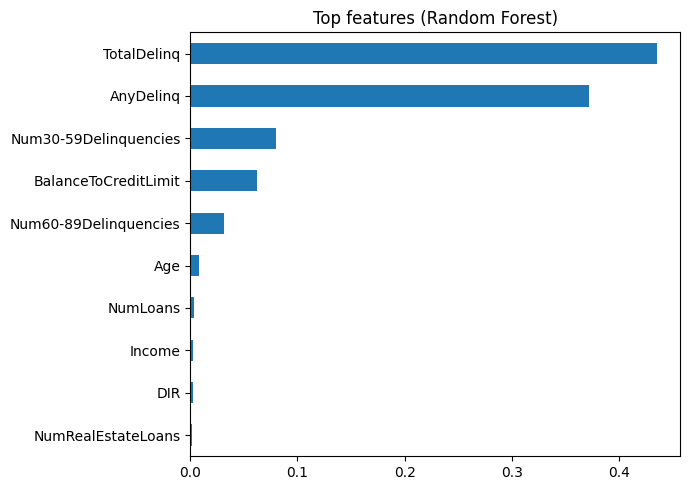

In [ ]:
imp = pd.Series(models["Random Forest"].feature_importances_,
                index=X.columns).sort_values().tail(10)
imp.plot.barh(figsize=(7,5), title="Top features (Random Forest)")
plt.tight_layout(); plt.show()

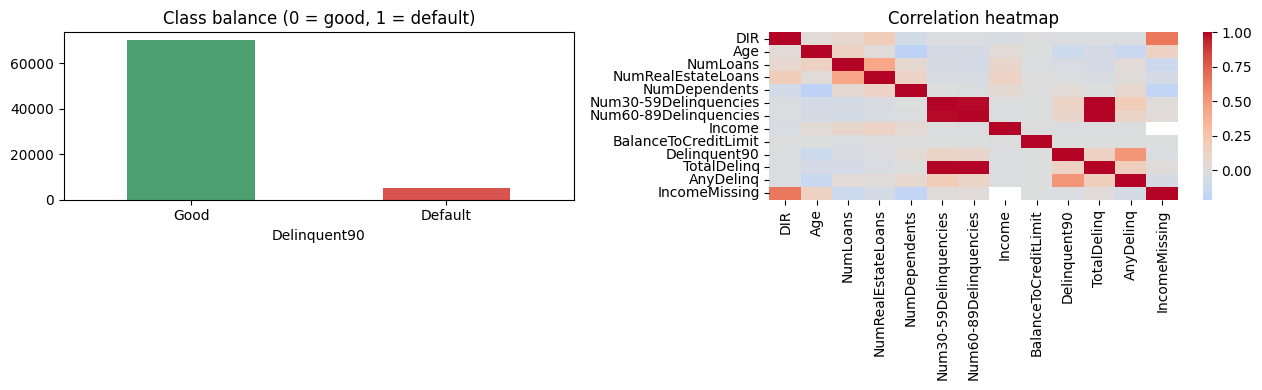

In [ ]:
import seaborn as sns
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
y.value_counts().plot.bar(ax=ax[0], color=["#4C9F70", "#D9534F"])
ax[0].set_title("Class balance (0 = good, 1 = default)")
ax[0].set_xticklabels(["Good", "Default"], rotation=0)
sns.heatmap(df.drop(columns="client_id").corr(numeric_only=True),
            cmap="coolwarm", center=0, ax=ax[1])
ax[1].set_title("Correlation heatmap")
plt.tight_layout(); plt.show()

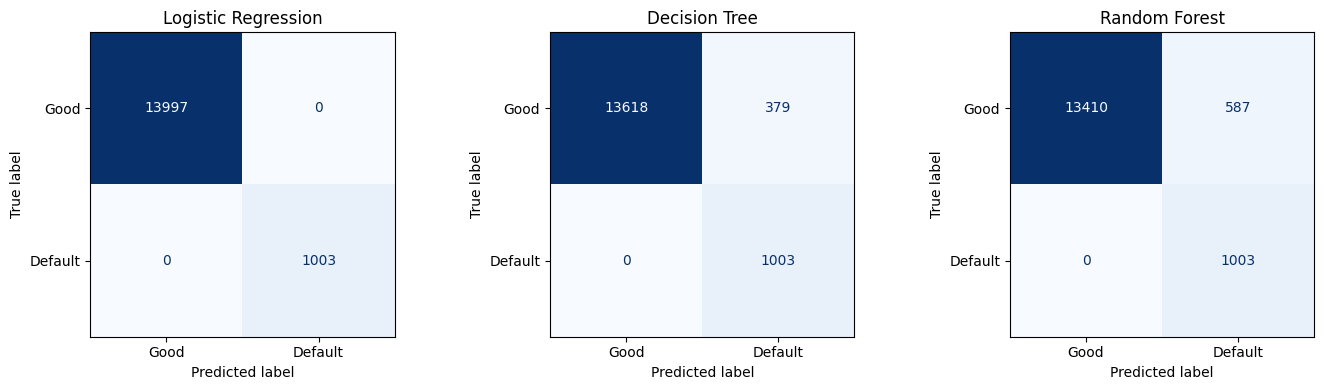

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, m) in zip(axes, models.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, m.predict(X_test)),
        display_labels=["Good", "Default"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
plt.tight_layout(); plt.show()

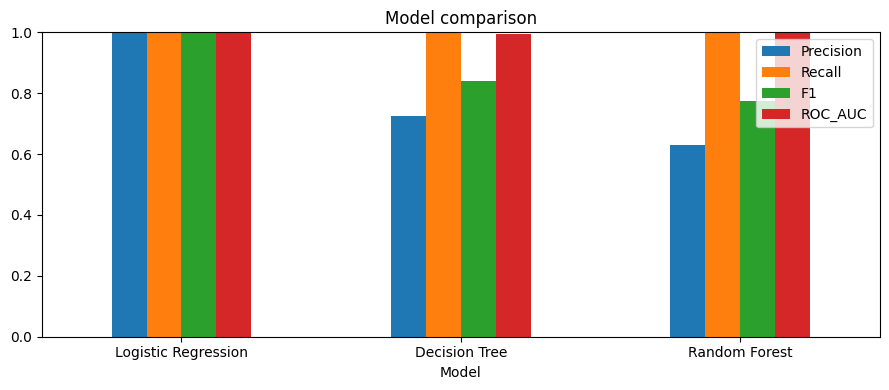

,Precision,Recall,F1,ROC_AUC
Model,,,,
Logistic Regression,1.000,1.0,1.000,1.000
Decision Tree,0.726,1.0,0.841,0.996
Random Forest,0.631,1.0,0.774,0.998


In [ ]:
results = pd.DataFrame(rows, columns=["Model","Precision","Recall","F1","ROC_AUC"]).set_index("Model")
results.round(3).plot.bar(figsize=(9, 4), rot=0)
plt.title("Model comparison"); plt.ylim(0, 1); plt.tight_layout(); plt.show()
results.round(3)

In [ ]:
best_name = results["ROC_AUC"].idxmax()
best = models[best_name]
print("Best model:", best_name)

proba = best.predict_proba(X_test)[:, 1]
out = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    p = (proba >= t).astype(int)
    out.append([t, precision_score(y_test, p, zero_division=0),
                recall_score(y_test, p), f1_score(y_test, p)])
pd.DataFrame(out, columns=["Threshold", "Precision", "Recall", "F1"]).round(3)

Best model: Logistic Regression


,Threshold,Precision,Recall,F1
0,0.3,1.0,1.0,1.0
1,0.4,1.0,1.0,1.0
2,0.5,1.0,1.0,1.0
3,0.6,1.0,1.0,1.0
4,0.7,1.0,1.0,1.0
5,0.8,1.0,1.0,1.0


Target column: Delinquent90
Delinquent90
0    0.933
1    0.067
Name: proportion, dtype: float64
===== Logistic Regression
              precision    recall  f1-score   support

           0       0.97      0.82      0.89     13997
           1       0.20      0.60      0.30      1003

    accuracy                           0.81     15000
   macro avg       0.58      0.71      0.59     15000
weighted avg       0.92      0.81      0.85     15000

===== Decision Tree
              precision    recall  f1-score   support

           0       0.98      0.76      0.85     13997
           1       0.18      0.75      0.29      1003

    accuracy                           0.76     15000
   macro avg       0.58      0.75      0.57     15000
weighted avg       0.92      0.76      0.82     15000

===== Random Forest
              precision    recall  f1-score   support

           0       0.98      0.81      0.88     13997
           1       0.21      0.72      0.33      1003

    accuracy        

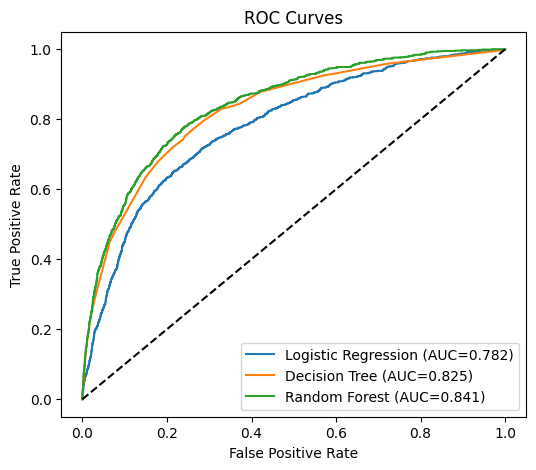

                     Precision  Recall     F1  ROC_AUC
Model                                                 
Logistic Regression      0.196   0.603  0.296    0.782
Decision Tree            0.182   0.751  0.293    0.825
Random Forest            0.212   0.723  0.328    0.841


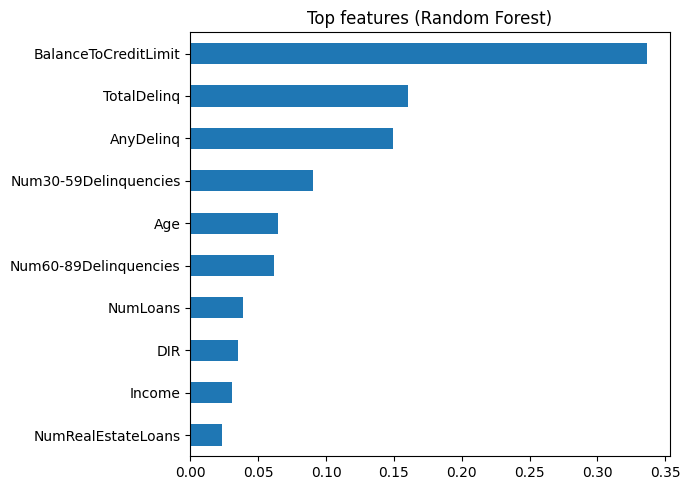

Best model: Random Forest
risk_band
Low       43354
Medium    20176
High      11470
Name: count, dtype: int64


,client_id,default_probability,risk_band
0,75000,0.398924,Medium
1,75001,0.909941,High
2,75002,0.099109,Low
3,75003,0.414306,Medium
4,75004,0.081771,Low
5,75005,0.141641,Low
6,75006,0.122724,Low
7,75007,0.169182,Low
8,75008,0.347430,Medium
9,75009,0.500506,Medium


In [4]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, roc_auc_score, roc_curve,
                             precision_score, recall_score, f1_score)

df = pd.read_csv("credit_scoring_train.csv")
test = pd.read_csv("credit_scoring_test.csv")

cands = [c for c in df.columns if df[c].nunique() == 2 and c != "client_id"]
TARGET = cands[-1]
print("Target column:", TARGET)
print(df[TARGET].value_counts(normalize=True).round(3))

delinq = [c for c in df.columns if "Delinq" in c and c != TARGET]
dir_cap = df["DIR"].quantile(0.99)

def prepare(d):
    d = d.copy()
    d["TotalDelinq"] = d[delinq].sum(axis=1)
    d["AnyDelinq"] = (d["TotalDelinq"] > 0).astype(int)
    d["IncomeMissing"] = d["Income"].isna().astype(int)
    d["DIR"] = d["DIR"].clip(upper=dir_cap)
    d = d.drop(columns=[c for c in ["client_id", TARGET] if c in d.columns])
    return pd.get_dummies(d, drop_first=True, dtype=int)

df = df.drop_duplicates()
y = df[TARGET]
X = prepare(df)
med = X.median()
X = X.fillna(med)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
models = {
 "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000)),
 "Decision Tree": DecisionTreeClassifier(max_depth=5, min_samples_leaf=50, class_weight="balanced", random_state=42),
 "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=8, min_samples_leaf=20, class_weight="balanced", random_state=42, n_jobs=-1),
}
rows = []
plt.figure(figsize=(6,5))
for name, m in models.items():
    m.fit(X_train, y_train)
    proba = m.predict_proba(X_test)[:,1]; pred = m.predict(X_test)
    print("=====", name); print(classification_report(y_test, pred))
    rows.append([name, precision_score(y_test,pred), recall_score(y_test,pred), f1_score(y_test,pred), roc_auc_score(y_test,proba)])
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC={rows[-1][4]:.3f})")
plt.plot([0,1],[0,1],"k--"); plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curves"); plt.legend(); plt.show()
results = pd.DataFrame(rows, columns=["Model","Precision","Recall","F1","ROC_AUC"]).set_index("Model").round(3)
print(results)

imp = pd.Series(models["Random Forest"].feature_importances_, index=X.columns).sort_values().tail(10)
imp.plot.barh(figsize=(7,5), title="Top features (Random Forest)"); plt.tight_layout(); plt.show()

best_name = results["ROC_AUC"].idxmax(); best = models[best_name]
print("Best model:", best_name)

t = prepare(test).reindex(columns=X.columns, fill_value=0).fillna(med)
result = pd.DataFrame({"client_id": test["client_id"], "default_probability": best.predict_proba(t)[:,1]})
result["risk_band"] = pd.cut(result["default_probability"], [0,0.3,0.6,1.0], labels=["Low","Medium","High"], include_lowest=True)
print(result["risk_band"].value_counts())
result.to_csv("predictions.csv", index=False)
result.head(10)

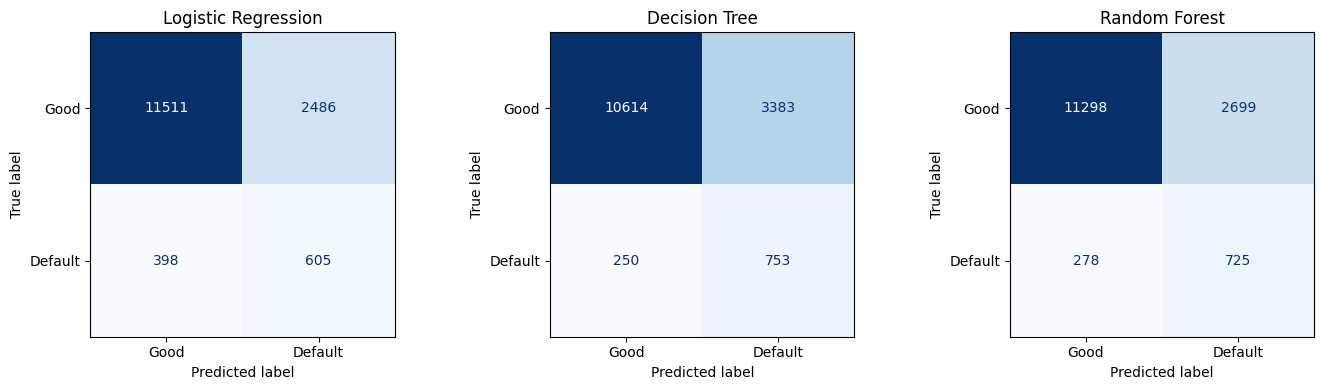

In [5]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, m) in zip(axes, models.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, m.predict(X_test)),
        display_labels=["Good", "Default"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
plt.tight_layout(); plt.show()

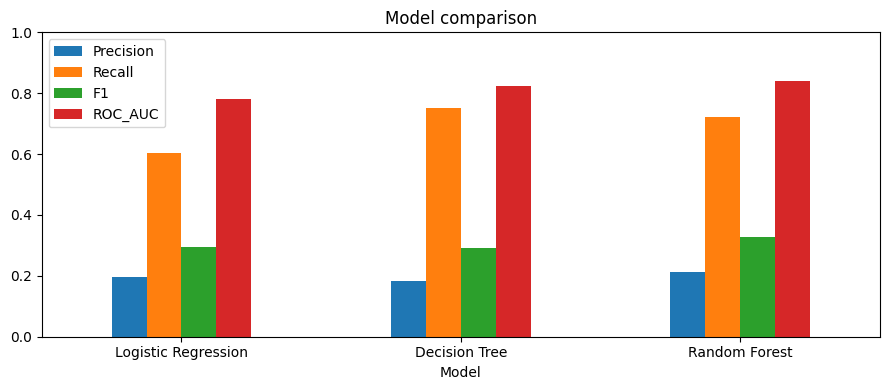

In [6]:
results.plot.bar(figsize=(9, 4), rot=0)
plt.title("Model comparison"); plt.ylim(0, 1); plt.tight_layout(); plt.show()

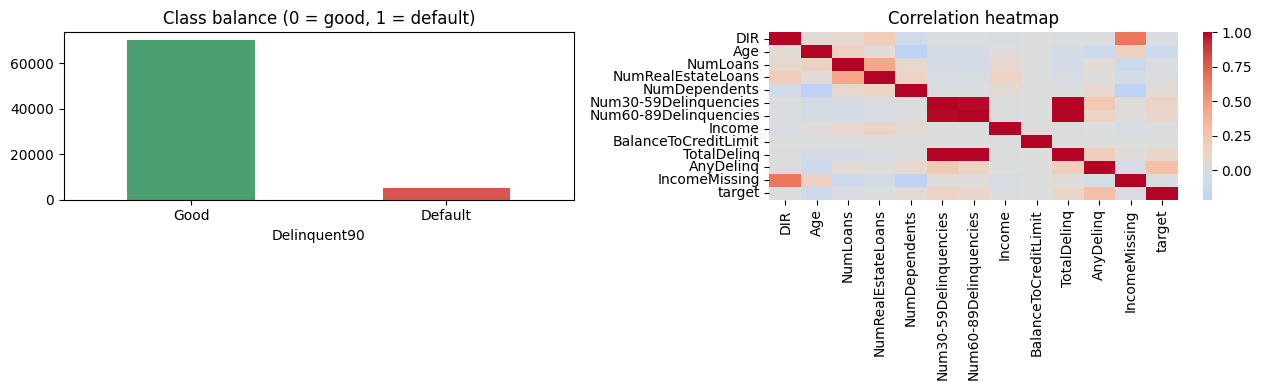

In [7]:
import seaborn as sns
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
y.value_counts().plot.bar(ax=ax[0], color=["#4C9F70", "#D9534F"])
ax[0].set_title("Class balance (0 = good, 1 = default)")
ax[0].set_xticklabels(["Good", "Default"], rotation=0)
sns.heatmap(X.assign(target=y).corr(), cmap="coolwarm", center=0, ax=ax[1])
ax[1].set_title("Correlation heatmap")
plt.tight_layout(); plt.show()

In [8]:
proba = best.predict_proba(X_test)[:, 1]
out = []
for th in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    p = (proba >= th).astype(int)
    out.append([th, precision_score(y_test, p, zero_division=0),
                recall_score(y_test, p), f1_score(y_test, p)])
pd.DataFrame(out, columns=["Threshold", "Precision", "Recall", "F1"]).round(3)

,Threshold,Precision,Recall,F1
0,0.3,0.138,0.869,0.238
1,0.4,0.165,0.815,0.274
2,0.5,0.212,0.723,0.328
3,0.6,0.265,0.610,0.370
4,0.7,0.322,0.486,0.387
5,0.8,0.405,0.372,0.388


In [9]:
from google.colab import files
files.download("predictions.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>